# Final Model Comparison Notebook

This notebook loads saved experiment outputs from Random Forest, XGBoost, and RUSBoost, then compares the models across:

- Step 4 thresholding
- Step 5 calibration
- Step 6 conformal prediction
- Step 7 cost-aware deferral tuning
- Step 9 final held-out evaluation
- Raw vs processed performance
- Safety metrics
- Cost-aware decision quality
- Coverage vs deferral trade-off

**Before running:** update the three experiment paths in the next cell.

In [21]:
import os
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

DEFINE PATHS TO YOUR EXPERIMENTS

In [23]:
models = {
    "RandomForest": "experiments_rf",
    "XGBoost": "experiments_xgboost",
    "RUSBoost": "experiments_rusboost"
}

LOAD LATEST RUN FOR EACH MODEL

In [24]:
def get_latest_run(folder):
    runs = sorted(Path(folder).glob("run_*"), reverse=True)
    return runs[0] if runs else None


all_results = {}

for model_name, folder in models.items():
    run_path = get_latest_run(folder)

    if run_path is None:
        print(f"No runs found for {model_name}")
        continue

    print(f"Loading {model_name} from {run_path}")

    with open(run_path / "full_pipeline_results.json", "r") as f:
        results = json.load(f)

    with open(run_path / "deferred_case_summary.json", "r") as f:
        deferred_case_summary = json.load(f)

    with open(run_path / "summary_metrics.json", "r") as f:
        summary_metrics = json.load(f)

    calibration_records_df = pd.read_csv(run_path / "step5_step6_calibration_records.csv")
    deferral_df = pd.read_csv(run_path / "step7_deferral_search.csv")
    test_df = pd.read_csv(run_path / "step9_test_predictions.csv")


    all_results[model_name] = {
        "results": results,
        "deferred_case_summary": deferred_case_summary,
        "summary_metrics": summary_metrics,
        "calibration_records_df": calibration_records_df,
        "deferral_df": deferral_df,
        "test_df": test_df
    }

Loading RandomForest from experiments_rf/run_2026-05-20_13-27-11
Loading XGBoost from experiments_xgboost/run_2026-05-20_13-29-57
Loading RUSBoost from experiments_rusboost/run_2026-05-20_13-28-56


In [25]:
for model_name, data in all_results.items():
    print("\n", model_name)
    print(data["results"].keys())


 RandomForest
dict_keys(['model', 'step4_thresholding', 'step5_calibration', 'step6_conformal', 'step7_deferral', 'step9_final', 'artifacts', 'deferred_case_summary'])

 XGBoost
dict_keys(['model', 'step4_thresholding', 'step5_calibration', 'step6_conformal', 'step7_deferral', 'step9_final', 'artifacts', 'deferred_case_summary'])

 RUSBoost
dict_keys(['model', 'step4_thresholding', 'step5_calibration', 'step6_conformal', 'step7_deferral', 'step9_final', 'artifacts', 'deferred_case_summary'])


BASE PAPER EVALUATION (RAW vs FINAL)

In [26]:
base_eval_rows = []

for model_name, data in all_results.items():
    r = data["results"]
    test_df = data["test_df"]

    # RAW (no deferral)
    raw_preds = test_df["base_pred"]
    y_true = test_df["y_true"]

    from sklearn.metrics import recall_score, confusion_matrix, roc_auc_score, average_precision_score

    fn = ((raw_preds == 0) & (y_true == 1)).sum()

    row = {
        "Model": model_name,

        # RAW MODEL
        "Recall (Raw)": recall_score(y_true, raw_preds),
        "FN (Raw)": fn,

        # FINAL MODEL (with deferral)
        "Recall (Final)": r["step9_final"]["selective_prediction_test"]["retained_recall"],
        "FN (Final)": r["step9_final"]["selective_prediction_test"]["fn"],

        # Performance
        "ROC-AUC": r["step9_final"]["overall_test"]["roc_auc"],
        "PR-AUC": r["step9_final"]["overall_test"]["pr_auc"]
    }

    base_eval_rows.append(row)

base_eval_df = pd.DataFrame(base_eval_rows)
base_eval_df

,Model,Recall (Raw),FN (Raw),Recall (Final),FN (Final),ROC-AUC,PR-AUC
0,RandomForest,0.911765,6,0.823529,6,0.957694,0.715609
1,XGBoost,0.911765,6,0.625000,6,0.966858,0.695197
2,RUSBoost,0.926471,5,0.761905,5,0.955684,0.630678


FULL COMPARISON TABLE (ALL STEPS)

In [27]:
comparison_rows = []

for model_name, data in all_results.items():
    r = data["results"]

    row = {
        "Model": model_name,

        # Step 4
        "Threshold": r["step4_thresholding"]["base_threshold"],

        # Step 5
        "Brier Score": r["step5_calibration"]["brier_score"],
        "Log Loss": r["step5_calibration"]["log_loss"],

        # Step 6
        "CP Coverage": r["step6_conformal"]["coverage_cal"],
        "CP Avg Set Size": r["step6_conformal"]["avg_set_size_cal"],

        # Step 7
        "Best Tau": r["step7_deferral"]["best_tau"],
        "Cost (Cal)": r["step7_deferral"]["best_cost_per_sample"],

        # Step 9 FINAL
        "ROC-AUC": r["step9_final"]["overall_test"]["roc_auc"],
        "PR-AUC": r["step9_final"]["overall_test"]["pr_auc"],

        "Final Coverage": r["step9_final"]["selective_prediction_test"]["coverage"],
        "Deferred %": r["step9_final"]["selective_prediction_test"]["deferred_fraction"],
        "Final Cost": r["step9_final"]["selective_prediction_test"]["cost_per_sample"],
        "Retained Recall": r["step9_final"]["selective_prediction_test"]["retained_recall"]
    }

    comparison_rows.append(row)

comparison_df = pd.DataFrame(comparison_rows)
comparison_df.sort_values("Final Cost")

,Model,Threshold,Brier Score,Log Loss,CP Coverage,CP Avg Set Size,Best Tau,Cost (Cal),ROC-AUC,PR-AUC,Final Coverage,Deferred %,Final Cost,Retained Recall
2,RUSBoost,0.034747,0.017486,0.058871,0.9215,0.9270,0.5,0.2055,0.955684,0.630678,0.941,0.059,0.2105,0.761905
0,RandomForest,0.034747,0.016433,0.059883,0.9190,0.9235,0.5,0.2490,0.957694,0.715609,0.941,0.059,0.2185,0.823529
1,XGBoost,0.014949,0.014848,0.053021,0.9125,0.9170,0.5,0.2375,0.966858,0.695197,0.925,0.075,0.2465,0.625000


ECE (Expected Calibration Error) FUNCTION

In [28]:
def compute_ece(y_true, y_prob, n_bins=10):
    """
    Expected Calibration Error (ECE)
    """
    y_true = np.array(y_true)
    y_prob = np.array(y_prob)

    bins = np.linspace(0, 1, n_bins + 1)
    bin_ids = np.digitize(y_prob, bins) - 1

    ece = 0.0

    for i in range(n_bins):
        mask = bin_ids == i
        if np.sum(mask) > 0:
            bin_acc = np.mean(y_true[mask])
            bin_conf = np.mean(y_prob[mask])
            ece += np.abs(bin_acc - bin_conf) * np.sum(mask) / len(y_true)

    return ece

COMPUTE ECE FOR ALL MODELS

In [29]:
ece_results = []

for model_name, data in all_results.items():
    test_df = data["test_df"]

    y_true = test_df["y_true"]
    y_prob = test_df["p1"]

    ece = compute_ece(y_true, y_prob, n_bins=10)

    ece_results.append({
        "Model": model_name,
        "ECE": ece
    })

ece_df = pd.DataFrame(ece_results)
ece_df

,Model,ECE
0,RandomForest,0.002998
1,XGBoost,0.002517
2,RUSBoost,0.007055


VISUALIZE ECE for all models

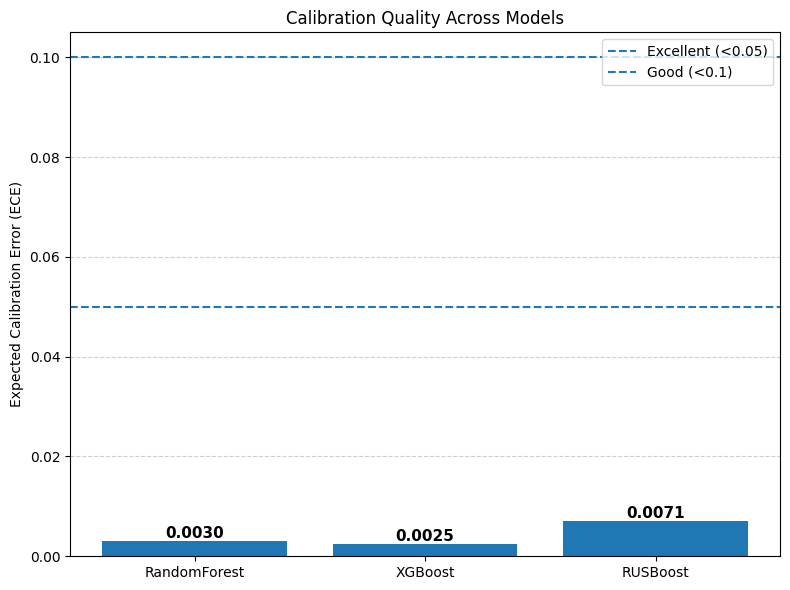

In [30]:
plt.figure(figsize=(8,6))

bars = plt.bar(
    ece_df["Model"],
    ece_df["ECE"]
)

# Annotate values
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        height,
        f"{height:.4f}",
        ha='center',
        va='bottom',
        fontsize=11,
        fontweight='bold'
    )

# Reference lines (like paper)
plt.axhline(0.05, linestyle='--', label='Excellent (<0.05)')
plt.axhline(0.10, linestyle='--', label='Good (<0.1)')

plt.ylabel("Expected Calibration Error (ECE)")
plt.title("Calibration Quality Across Models")

plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

RISK–COVERAGE CURVE

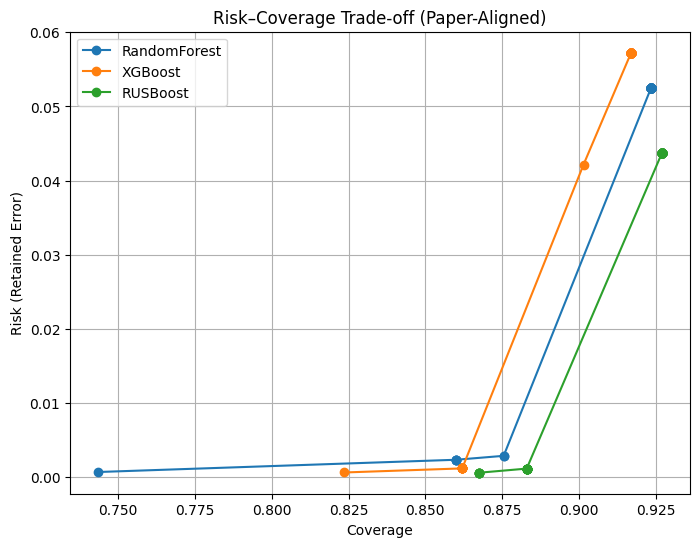

In [31]:
plt.figure(figsize=(8,6))

for model_name, data in all_results.items():
    df = data["deferral_df"].copy()

    #Sort by coverage (CRITICAL)
    df = df.sort_values("coverage")

    plt.plot(
        df["coverage"],
        df["retained_error"],   #THIS is the paper's "risk"
        marker='o',
        label=model_name
    )

plt.xlabel("Coverage")
plt.ylabel("Risk (Retained Error)")
plt.title("Risk–Coverage Trade-off (Paper-Aligned)")
plt.legend()
plt.grid(True)
plt.show()

COST–COVERAGE CURVE

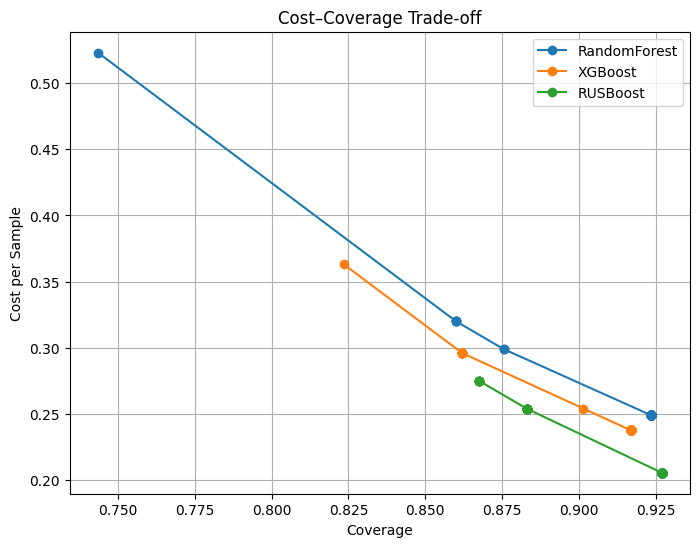

In [32]:
plt.figure(figsize=(8,6))

for model_name, data in all_results.items():
    df = data["deferral_df"]

    plt.plot(
        df["coverage"],
        df["cost_per_sample"],
        marker='o',
        label=model_name
    )

plt.xlabel("Coverage")
plt.ylabel("Cost per Sample")
plt.title("Cost–Coverage Trade-off")
plt.legend()
plt.grid(True)
plt.show()

 DEFERRAL vs ERROR

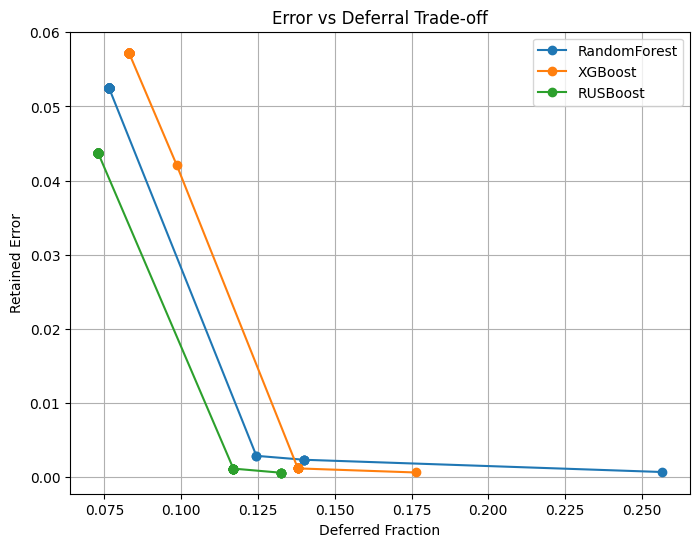

In [33]:
plt.figure(figsize=(8,6))

for model_name, data in all_results.items():
    df = data["deferral_df"]

    plt.plot(
        df["deferred_fraction"],
        df["retained_error"],
        marker='o',
        label=model_name
    )

plt.xlabel("Deferred Fraction")
plt.ylabel("Retained Error")
plt.title("Error vs Deferral Trade-off")
plt.legend()
plt.grid(True)
plt.show()

RAW vs FINAL SAFETY

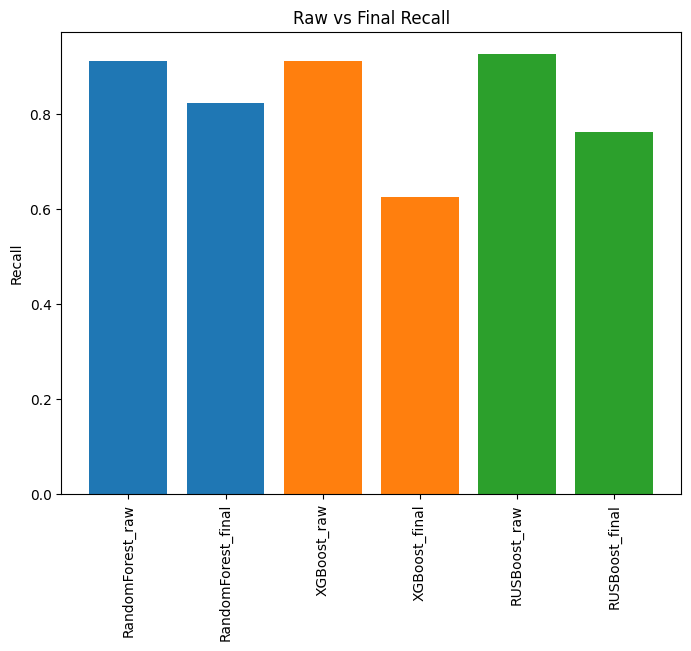

In [34]:
plt.figure(figsize=(8,6))

for model_name, data in all_results.items():
    test_df = data["test_df"]
    r = data["results"]

    raw_recall = (test_df["base_pred"] & test_df["y_true"]).sum() / max(test_df["y_true"].sum(), 1)
    final_recall = r["step9_final"]["selective_prediction_test"]["retained_recall"]

    plt.bar([model_name + "_raw", model_name + "_final"], [raw_recall, final_recall])

plt.ylabel("Recall")
plt.title("Raw vs Final Recall")
plt.xticks(rotation=90)
plt.show()

Models vs Trivial/Random Baseline Comparison Table

In [35]:
from sklearn.metrics import roc_auc_score, average_precision_score

table_rows = []

for model_name, data in all_results.items():
    test_df = data["test_df"]

    y_true = test_df["y_true"]
    y_pred = test_df["base_pred"]      # ✅ NO DEFERRAL
    y_prob = test_df["p1"]

    # -----------------------------
    # MODEL METRICS
    # -----------------------------
    error_rate = (y_pred != y_true).mean()
    auroc = roc_auc_score(y_true, y_prob)
    auprc = average_precision_score(y_true, y_prob)

    # -----------------------------
    # TRIVIAL BASELINE (always negative)
    # -----------------------------
    y_pred_baseline = np.zeros_like(y_true)

    baseline_error = (y_pred_baseline != y_true).mean()

    # For AUROC baseline = 0.5
    baseline_auroc = 0.5

    # AUPRC baseline = prevalence
    prevalence = y_true.mean()
    baseline_auprc = prevalence

    # -----------------------------
    # ADD ROWS
    # -----------------------------
    table_rows.append({
        "Model": f"{model_name} (Model)",
        "Error Rate (%)": round(error_rate * 100, 2),
        "AUROC": round(auroc, 4),
        "AUPRC": round(auprc, 4)
    })

    table_rows.append({
        "Model": f"{model_name} (Baseline)",
        "Error Rate (%)": round(baseline_error * 100, 2),
        "AUROC": baseline_auroc,
        "AUPRC": round(baseline_auprc, 4)
    })

table_df = pd.DataFrame(table_rows)
table_df

,Model,Error Rate (%),AUROC,AUPRC
0,RandomForest (Model),8.55,0.9577,0.7156
1,RandomForest (Baseline),3.40,0.5000,0.0340
2,XGBoost (Model),8.85,0.9669,0.6952
3,XGBoost (Baseline),3.40,0.5000,0.0340
4,RUSBoost (Model),8.05,0.9557,0.6307
5,RUSBoost (Baseline),3.40,0.5000,0.0340


Plot of the Models vs Trivial/Random Baseline at 100% Coverage

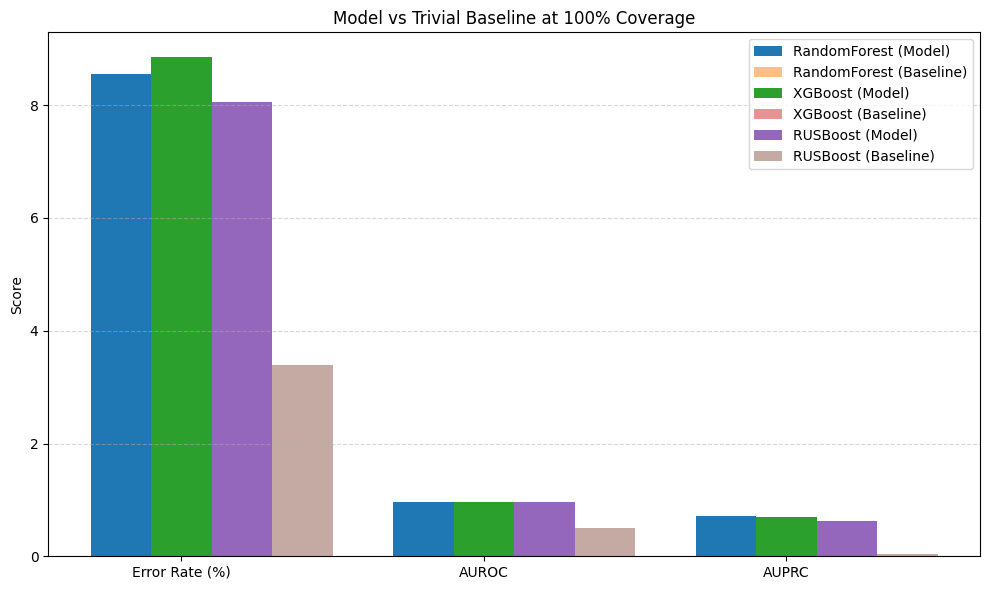

In [36]:
import matplotlib.pyplot as plt
import numpy as np

metrics = ["Error Rate (%)", "AUROC", "AUPRC"]

x = np.arange(len(metrics))
width = 0.2

plt.figure(figsize=(10,6))

for i, (model_name, data) in enumerate(all_results.items()):
    test_df = data["test_df"]

    y_true = test_df["y_true"]
    y_pred = test_df["base_pred"]
    y_prob = test_df["p1"]

    # Model metrics
    model_vals = [
        (y_pred != y_true).mean() * 100,
        roc_auc_score(y_true, y_prob),
        average_precision_score(y_true, y_prob)
    ]

    # Baseline metrics
    baseline_vals = [
        (np.zeros_like(y_true) != y_true).mean() * 100,
        0.5,
        y_true.mean()
    ]

    # Plot
    plt.bar(x + i*width, model_vals, width, label=f"{model_name} (Model)")
    plt.bar(x + i*width + width, baseline_vals, width, alpha=0.5, label=f"{model_name} (Baseline)")

plt.xticks(x + width, metrics)
plt.ylabel("Score")
plt.title("Model vs Trivial Baseline at 100% Coverage")
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [37]:
from sklearn.metrics import roc_curve, auc, precision_recall_curve
import matplotlib.pyplot as plt
import numpy as np

ROC CURVES

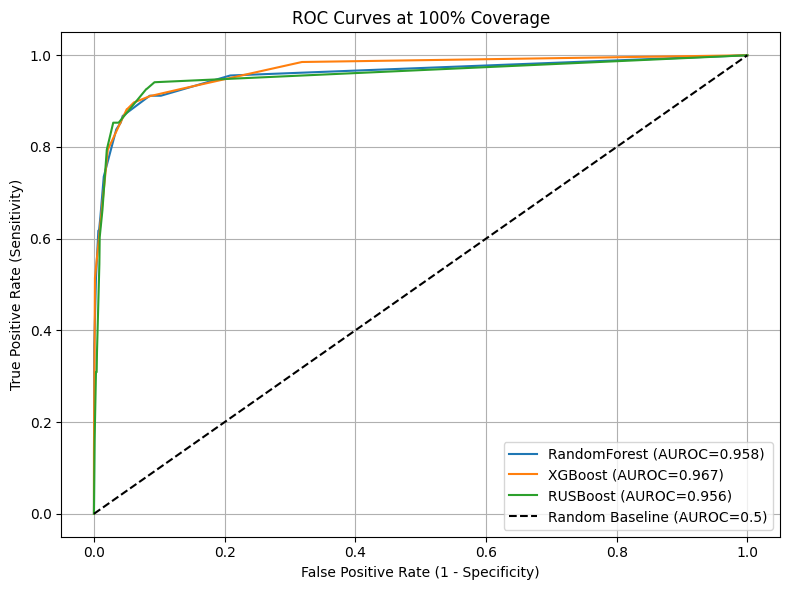

In [38]:
plt.figure(figsize=(8,6))

for model_name, data in all_results.items():
    test_df = data["test_df"]

    y_true = test_df["y_true"]
    y_prob = test_df["p1"]

    fpr, tpr, _ = roc_curve(y_true, y_prob)
    roc_auc = auc(fpr, tpr)

    plt.plot(fpr, tpr, label=f"{model_name} (AUROC={roc_auc:.3f})")

# Random baseline
plt.plot([0,1], [0,1], linestyle='--', color='black', label="Random Baseline (AUROC=0.5)")

plt.xlabel("False Positive Rate (1 - Specificity)")
plt.ylabel("True Positive Rate (Sensitivity)")
plt.title("ROC Curves at 100% Coverage")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

PRECISION–RECALL CURVES

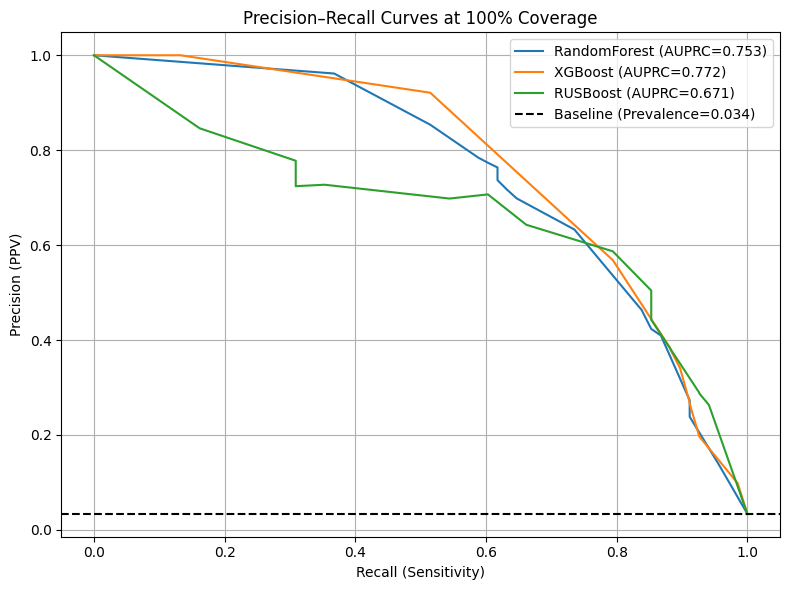

In [39]:
plt.figure(figsize=(8,6))

for model_name, data in all_results.items():
    test_df = data["test_df"]

    y_true = test_df["y_true"]
    y_prob = test_df["p1"]

    precision, recall, _ = precision_recall_curve(y_true, y_prob)
    pr_auc = auc(recall, precision)

    plt.plot(recall, precision, label=f"{model_name} (AUPRC={pr_auc:.3f})")

# Baseline = prevalence
prevalence = y_true.mean()
plt.axhline(prevalence, linestyle='--', color='black',
            label=f"Baseline (Prevalence={prevalence:.3f})")

plt.xlabel("Recall (Sensitivity)")
plt.ylabel("Precision (PPV)")
plt.title("Precision–Recall Curves at 100% Coverage")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

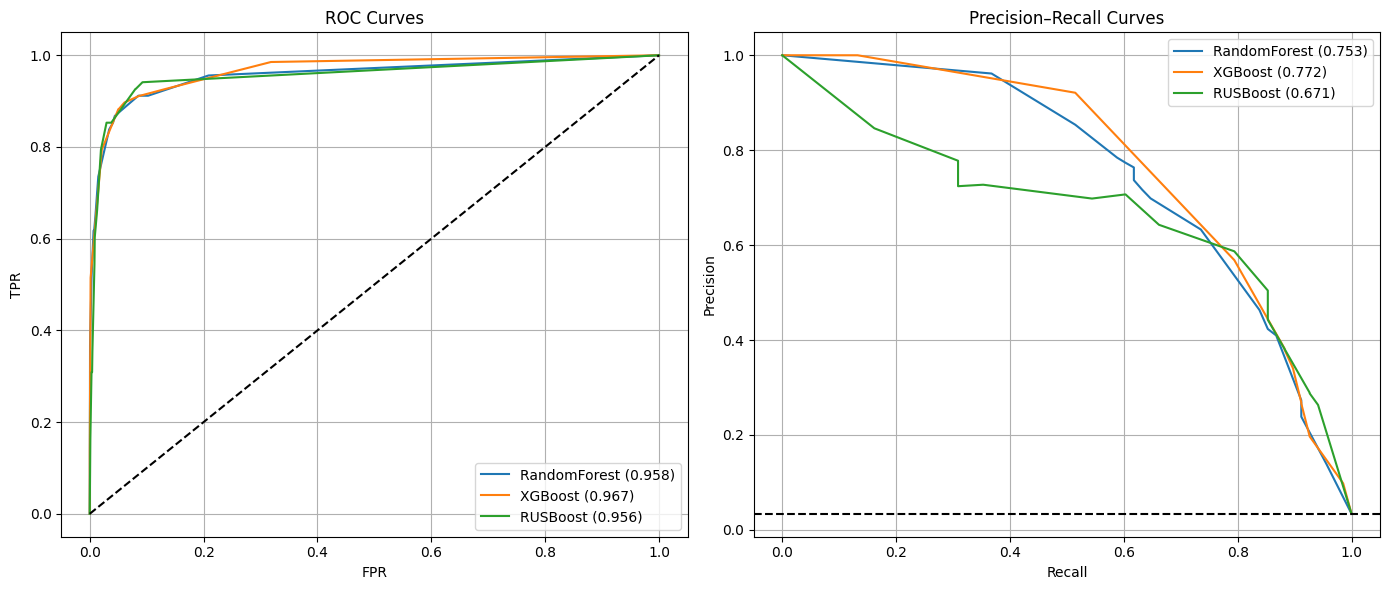

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(14,6))

# -------------------------
# ROC
# -------------------------
for model_name, data in all_results.items():
    test_df = data["test_df"]

    y_true = test_df["y_true"]
    y_prob = test_df["p1"]

    fpr, tpr, _ = roc_curve(y_true, y_prob)
    roc_auc = auc(fpr, tpr)

    axes[0].plot(fpr, tpr, label=f"{model_name} ({roc_auc:.3f})")

axes[0].plot([0,1], [0,1], linestyle='--', color='black')
axes[0].set_title("ROC Curves")
axes[0].set_xlabel("FPR")
axes[0].set_ylabel("TPR")
axes[0].legend()
axes[0].grid(True)

# -------------------------
# PR
# -------------------------
for model_name, data in all_results.items():
    test_df = data["test_df"]

    y_true = test_df["y_true"]
    y_prob = test_df["p1"]

    precision, recall, _ = precision_recall_curve(y_true, y_prob)
    pr_auc = auc(recall, precision)

    axes[1].plot(recall, precision, label=f"{model_name} ({pr_auc:.3f})")

prevalence = y_true.mean()
axes[1].axhline(prevalence, linestyle='--', color='black')

axes[1].set_title("Precision–Recall Curves")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

BEST OPERATING POINT

In [41]:
for model_name, data in all_results.items():
    df = data["deferral_df"]

    best = df.sort_values("cost_per_sample").iloc[0]

    print(f"\n=== {model_name} ===")
    print(f"Best Tau: {best['tau']:.3f}")
    print(f"Cost: {best['cost_per_sample']:.4f}")
    #print(f"Retained Error: {best['retained_error']:.4f}")
    print(f"Coverage: {best['coverage']:.4f}")
    print(f"Deferred: {best['deferred_fraction']:.4f}")


=== RandomForest ===
Best Tau: 0.500
Cost: 0.2490
Coverage: 0.9235
Deferred: 0.0765

=== XGBoost ===
Best Tau: 0.500
Cost: 0.2375
Coverage: 0.9170
Deferred: 0.0830

=== RUSBoost ===
Best Tau: 0.500
Cost: 0.2055
Coverage: 0.9270
Deferred: 0.0730
